In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    accuracy_score,
    recall_score,
    f1_score,
    classification_report
)

In [2]:
df = pd.read_excel("Datos_CLV_2026_Tec_v2.xlsx", sheet_name="Ventas_CLV_2022_2026")
print(df.shape)

(114501, 15)


In [3]:
df.head()

,fecha_documento,folio_abreviado,folio,articulo_id,clave_articulo,nombre_articulo,marca,precio_unitario,total_unidades,total_neto,nombre_cliente,estado,ciudad,cp,vendedor
0,11.09.2026,B00,B00013017,7688,MFTL374M2,MFT L37 4M2,VITA,172.413793,1,172.41,HUGO CARRILLO SANPEDRO SF,Ciudad de México,CDMX,6100.0,JAVIERCAD
1,11.09.2026,B00,B00013017,7895,MFTPL313R2.5,MFT PL31 3R2.5,VITA,172.413793,1,172.41,HUGO CARRILLO SANPEDRO SF,Ciudad de México,CDMX,6100.0,JAVIERCAD
2,11.09.2026,B00,B00013017,7985,MFTPU313R2.5,MFT PU31 3R2.5,VITA,172.413793,2,344.83,HUGO CARRILLO SANPEDRO SF,Ciudad de México,CDMX,6100.0,JAVIERCAD
3,11.09.2026,B00,B00013017,8258,MFTT464M2,MFT T46 4M2,VITA,172.413793,2,344.83,HUGO CARRILLO SANPEDRO SF,Ciudad de México,CDMX,6100.0,JAVIERCAD
4,11.09.2026,A00,A00018080,7613,MFTL332M2,MFT L33 2M2,VITA,156.740000,1,156.74,JUAN PEDRO OLVERA ALONSO,Querétaro,Querétaro,76079.0,SERGIO SANCHEZ


In [4]:
print(df[['fecha_documento', 'folio', 'nombre_cliente', 'total_neto']].isnull().sum())

fecha_documento    0
folio              0
nombre_cliente     0
total_neto         0
dtype: int64


In [5]:
print('Ventas con total_neto <= 0:', (df['total_neto'] <= 0).sum())

df = df.dropna(subset=['fecha_documento', 'folio', 'nombre_cliente', 'total_neto'])
df = df[df['total_neto'] > 0]

df['fecha'] = pd.to_datetime(df['fecha_documento'], format='%d.%m.%Y')
print('Registros después de limpiar:', df.shape[0])

Ventas con total_neto <= 0: 4729
Registros después de limpiar: 109772


In [6]:
corte = pd.Timestamp('2026-01-01')
historico = df[df['fecha'] < corte]
futuro = df[df['fecha'] >= corte]
print('Ventas históricas:', historico.shape[0])
print('Ventas 2026:', futuro.shape[0])

Ventas históricas: 92169
Ventas 2026: 17603


In [7]:
clientes = historico.groupby('nombre_cliente').agg(
    frecuencia=('folio', 'nunique'),
    monto_total=('total_neto', 'sum'),
    primera_compra=('fecha', 'min'),
    ultima_compra=('fecha', 'max')
)

clientes['recencia_dias'] = (corte - clientes['ultima_compra']).dt.days
clientes['antiguedad_dias'] = (corte - clientes['primera_compra']).dt.days
clientes['ticket_promedio'] = clientes['monto_total'] / clientes['frecuencia']
clientes.head()

,frecuencia,monto_total,primera_compra,ultima_compra,recencia_dias,antiguedad_dias,ticket_promedio
nombre_cliente,,,,,,,
MARTHA CUELLAR PIÑA,1,8534.48,2024-10-30,2024-10-30,428,428,8534.480000
3D DIGITAL DENTAL DESIGN,11,75587.88,2023-06-09,2025-03-24,283,937,6871.625455
3D FACTORY MEXICO,2,55356.90,2025-12-16,2025-12-16,16,16,27678.450000
A W A INFRAESTRUCTURA,1,724.12,2023-02-20,2023-02-20,1046,1046,724.120000
AARON RICARDO DEL ANGEL ZAMACONA SF,2,1810.33,2025-04-02,2025-09-29,94,274,905.165000


In [8]:
gasto_2026 = futuro.groupby('nombre_cliente')['total_neto'].sum()
clientes['gasto_2026'] = gasto_2026.reindex(clientes.index).fillna(0)

mediana = clientes.loc[clientes['gasto_2026'] > 0, 'gasto_2026'].median()
print('Mediana de gasto 2026:', round(mediana, 2))

clientes['nivel_2026'] = np.where(clientes['gasto_2026'] == 0, 'Perdido',
                          np.where(clientes['gasto_2026'] <= mediana, 'Bajo', 'Alto'))

clientes['nivel_2026'].value_counts()

Mediana de gasto 2026: 7200.0


nivel_2026
Perdido    3199
Alto        474
Bajo        474
Name: count, dtype: int64

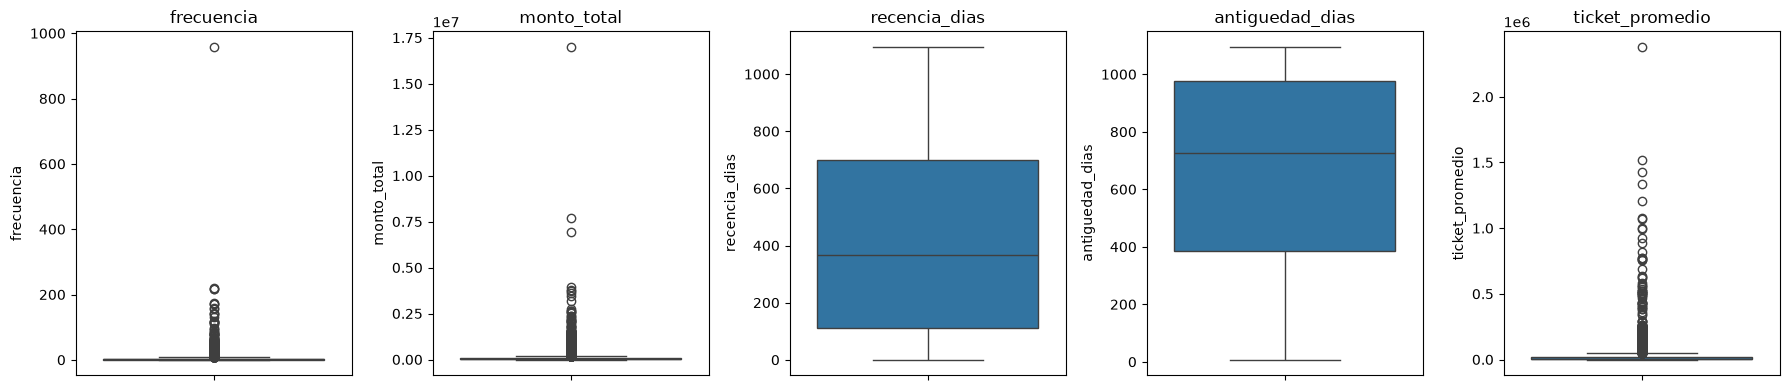

In [9]:
columnas = ['frecuencia', 'monto_total', 'recencia_dias', 'antiguedad_dias', 'ticket_promedio']

fig, axes = plt.subplots(1, len(columnas), figsize=(18, 4))
for ax, col in zip(axes, columnas):
    sns.boxplot(y=clientes[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [10]:
for col in columnas:
    Q1 = clientes[col].quantile(0.25)
    Q3 = clientes[col].quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR
    print(col, 'atípicos:', ((clientes[col] < lim_inf) | (clientes[col] > lim_sup)).sum())
    clientes[col] = clientes[col].clip(lim_inf, lim_sup)

frecuencia atípicos: 580
monto_total atípicos: 541
recencia_dias atípicos: 0
antiguedad_dias atípicos: 0
ticket_promedio atípicos: 671


In [11]:
for col in columnas:
    clientes['log_' + col] = np.log1p(clientes[col])

clientes[['log_' + c for c in columnas]].describe()

,log_frecuencia,log_monto_total,log_recencia_dias,log_antiguedad_dias,log_ticket_promedio
count,4147.000000,4147.000000,4147.000000,4147.000000,4147.000000
mean,1.204876,9.329624,5.539186,6.246748,8.410352
std,0.589463,1.944623,1.224358,0.894015,1.599292
min,0.693147,0.620576,0.693147,2.197225,0.620576
25%,0.693147,7.764043,4.736198,5.955837,7.103741
50%,1.098612,9.260046,5.905362,6.590301,8.243475
75%,1.609438,11.144047,6.553933,6.884997,9.861995
max,2.251292,12.039699,6.999422,6.999422,10.739503


In [12]:
Vars_Indep = clientes[['log_frecuencia', 'log_monto_total', 'log_recencia_dias',
                       'log_antiguedad_dias', 'log_ticket_promedio']]
Var_Dep = clientes['nivel_2026']

In [13]:
X = Vars_Indep
y = Var_Dep

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [15]:
escalar = StandardScaler()
X_train = escalar.fit_transform(X_train)
X_test = escalar.transform(X_test)

In [16]:
algoritmo = LogisticRegression(
    solver='lbfgs',
    max_iter=1000
)

In [17]:
algoritmo.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [18]:
y_pred = algoritmo.predict(X_test)
y_pred

array(['Bajo', 'Perdido', 'Perdido', ..., 'Alto', 'Perdido', 'Perdido'],
      shape=(1245,), dtype=object)

In [19]:
print('Clases del modelo:')
print(algoritmo.classes_)

Clases del modelo:
['Alto' 'Bajo' 'Perdido']


In [20]:
matriz = confusion_matrix(y_test, y_pred, labels=algoritmo.classes_)
print('Matriz de confusión:')
print(matriz)

Matriz de confusión:
[[ 71   4  67]
 [ 18  29  95]
 [ 25  10 926]]


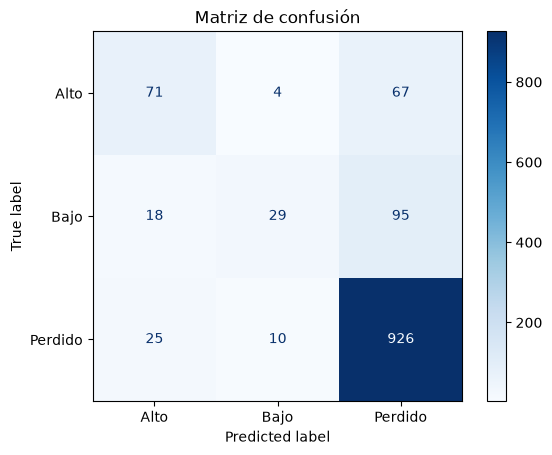

In [21]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=algoritmo.classes_
)
disp.plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusión')
plt.show()

In [22]:
precision = precision_score(y_test, y_pred, labels=algoritmo.classes_, average=None, zero_division=0)
print('Precisión por clase:')
print(pd.Series(precision, index=algoritmo.classes_).round(3))
print('Precisión ponderada:', round(precision_score(y_test, y_pred, average='weighted', zero_division=0), 3))

Precisión por clase:
Alto       0.623
Bajo       0.674
Perdido    0.851
dtype: float64
Precisión ponderada: 0.805


In [23]:
exactitud = accuracy_score(y_test, y_pred)
print('Exactitud del modelo:')
print(exactitud)

Exactitud del modelo:
0.8240963855421687


In [24]:
sensibilidad = recall_score(y_test, y_pred, labels=algoritmo.classes_, average=None, zero_division=0)
print('Sensibilidad por clase:')
print(pd.Series(sensibilidad, index=algoritmo.classes_).round(3))
print('Sensibilidad ponderada:', round(recall_score(y_test, y_pred, average='weighted', zero_division=0), 3))

Sensibilidad por clase:
Alto       0.500
Bajo       0.204
Perdido    0.964
dtype: float64
Sensibilidad ponderada: 0.824


In [25]:
puntajef1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
print('Puntaje F1 ponderado del modelo:')
print(puntajef1)

Puntaje F1 ponderado del modelo:
0.796698568011378


In [26]:
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

        Alto       0.62      0.50      0.55       142
        Bajo       0.67      0.20      0.31       142
     Perdido       0.85      0.96      0.90       961

    accuracy                           0.82      1245
   macro avg       0.72      0.56      0.59      1245
weighted avg       0.80      0.82      0.80      1245



In [27]:
probabilidades = algoritmo.predict_proba(X_test)
df_probabilidades = pd.DataFrame(
    probabilidades,
    columns=[f'Probabilidad_{clase}' for clase in algoritmo.classes_]
)
df_probabilidades.head()

,Probabilidad_Alto,Probabilidad_Bajo,Probabilidad_Perdido
0,0.166010,0.427212,0.406778
1,0.416868,0.099672,0.483461
2,0.008162,0.053138,0.938700
3,0.031126,0.023304,0.945571
4,0.004827,0.101867,0.893306


In [28]:
comparacion = pd.DataFrame({
    'Clase real': y_test.reset_index(drop=True),
    'Clase predicha': pd.Series(y_pred)
})
comparacion.head(10)

,Clase real,Clase predicha
0,Bajo,Bajo
1,Perdido,Perdido
2,Perdido,Perdido
3,Perdido,Perdido
4,Perdido,Perdido
5,Perdido,Perdido
6,Perdido,Perdido
7,Alto,Perdido
8,Perdido,Perdido
9,Perdido,Perdido


Para este análisis se buscó predecir el nivel de valor de cada cliente en 2026 (Alto, Bajo o Perdido) usando su historial de compras de 2023 a 2025: frecuencia, monto total, recencia, antigüedad y ticket promedio. Primero se limpiaron los datos. Se eliminaron las ventas con importe 0, los valores atípicos se trataron con el método IQR y las variables se transformaron con logaritmo y estandarización, porque estaban muy sesgadas.

El modelo obtuvo una exactitud de 0.82, es decir, acierta el nivel del cliente en 8 de cada 10 casos. La clase que mejor predice es "Perdido", con una sensibilidad de 0.96: casi todos los clientes que dejaron de comprar en 2026 fueron identificados. Para CLV esto es lo más útil, porque permite saber con anticipación qué clientes hay que intentar retener.

La clase "Alto" tuvo una precisión de 0.62 y una sensibilidad de 0.50, así que el modelo encuentra a la mitad de los clientes más valiosos. La clase con peor resultado fue "Bajo", con una sensibilidad de 0.20. En la matriz de confusión se ve que la mayoría de estos clientes se clasificaron como "Perdido". Tiene sentido, porque un cliente que compra poco tiene un comportamiento muy parecido al de uno que está por dejar de comprar.

También hay que considerar que cerca del 77 % de los clientes están en la clase "Perdido". Ese desbalance hace que el modelo tienda a favorecerla. Para mejorar el modelo se podría balancear las clases o agregar otras variables, como la categoría de productos que compra cada cliente.